## Preliminaries

In [1]:
import pandas as pd
from src.extract import fetch_fred, fetch_prices
from src.preprocessing_functions import *

### Extract macro data

In [2]:
df_macro = fetch_fred()
df_macro.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1771 entries, 2020-01-01 to 2026-10-14
Freq: B
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   real_yield_10y           1696 non-null   float64
 1   breakeven_inflation_10y  1697 non-null   float64
 2   dxy_broad_goods          1694 non-null   float64
 3   treasury_10y_nominal     1696 non-null   float64
 4   vix_index                1738 non-null   float64
dtypes: float64(5)
memory usage: 83.0 KB


In [3]:
# Mostrar missings iniciales
show_missings(df_macro)

dxy_broad_goods            0.043478
real_yield_10y             0.042349
treasury_10y_nominal       0.042349
breakeven_inflation_10y    0.041784
vix_index                  0.018634
dtype: float64

In [4]:
# Missings aplicando forward fill
show_missings(df_macro.ffill())

real_yield_10y             0.000565
breakeven_inflation_10y    0.000565
dxy_broad_goods            0.000565
treasury_10y_nominal       0.000565
vix_index                  0.000565
dtype: float64

In [5]:
# Se aplica el forward fill y eliminan missings iniciales
df_macro = df_macro.ffill().dropna()

In [6]:
# Se aplica retardo de 1 dia para evitar Lookahead Bias (horario de publicación luego del cierre diario)
macro_cols = df_macro.columns.to_list()
df_macro = calculate_lag(df_macro,macro_cols)
show_missings(df_macro)

real_yield_10y_lag1             0.000565
breakeven_inflation_10y_lag1    0.000565
dxy_broad_goods_lag1            0.000565
treasury_10y_nominal_lag1       0.000565
vix_index_lag1                  0.000565
dtype: float64

In [7]:
# Se eliminan missings luego de aplicar el lag
df_macro = df_macro.dropna()

In [13]:
df_macro.tail()

,real_yield_10y_lag1,breakeven_inflation_10y_lag1,dxy_broad_goods_lag1,treasury_10y_nominal_lag1,vix_index_lag1
date,,,,,
2026-10-08,2.92,2.36,121.2558,5.28,15.08
2026-10-09,2.87,2.35,121.4469,5.22,15.41
2026-10-12,2.91,2.33,121.6023,5.24,14.84
2026-10-13,2.91,2.33,121.6023,5.24,15.21
2026-10-14,2.88,2.33,121.6023,5.21,15.27


### Extract prices

In [8]:
df_prices = fetch_prices()
df_prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 355 entries, 2020-01-01 to 2026-10-14
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   gold    355 non-null    float64
 1   oil     355 non-null    float64
 2   spy     355 non-null    float64
dtypes: float64(3)
memory usage: 11.1 KB


In [9]:
df_prices.tail()

Ticker,gold,oil,spy
date,,,
2026-09-16,4376.399902,94.589996,773.380005
2026-09-23,4179.700195,89.379997,764.200012
2026-09-30,4187.100098,89.440002,779.090027
2026-10-07,4177.299805,94.139999,778.010010
2026-10-14,4174.500000,95.209999,770.909973


In [10]:
# Se convierten las series de precios absolutos en retornos porcentuales
price_cols = df_prices.columns.to_list()
df_returns = calculate_return(df_prices, price_cols)
df_returns.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 355 entries, 2020-01-01 to 2026-10-14
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   gold_return  354 non-null    float64
 1   oil_return   354 non-null    float64
 2   spy_return   354 non-null    float64
dtypes: float64(3)
memory usage: 11.1 KB


In [11]:
# Se eliminan missings luego de calcular los retornos
df_returns = df_returns.dropna()

### Merge datasets

In [14]:
df_merged = df_macro.merge(df_returns, how='right', on= 'date')
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 354 entries, 2020-01-08 to 2026-10-14
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   real_yield_10y_lag1           354 non-null    float64
 1   breakeven_inflation_10y_lag1  354 non-null    float64
 2   dxy_broad_goods_lag1          354 non-null    float64
 3   treasury_10y_nominal_lag1     354 non-null    float64
 4   vix_index_lag1                354 non-null    float64
 5   gold_return                   354 non-null    float64
 6   oil_return                    354 non-null    float64
 7   spy_return                    354 non-null    float64
dtypes: float64(8)
memory usage: 24.9 KB


## EDA

In [15]:
df_merged.describe()

,real_yield_10y_lag1,breakeven_inflation_10y_lag1,dxy_broad_goods_lag1,treasury_10y_nominal_lag1,vix_index_lag1,gold_return,oil_return,spy_return
count,354.000000,354.000000,354.000000,354.000000,354.000000,354.000000,354.000000,354.000000
mean,0.918277,2.224435,119.565653,3.142712,20.713785,0.003085,0.004489,0.002752
std,1.274265,0.351793,4.165848,1.416865,7.439121,0.025395,0.085081,0.023925
min,-1.190000,0.630000,110.504600,0.520000,11.860000,-0.121042,-0.502238,-0.123500
25%,-0.530000,2.220000,116.547675,1.622500,16.032500,-0.010369,-0.027110,-0.006987
50%,1.565000,2.310000,120.050650,3.825000,18.735000,0.002985,0.005073,0.003667
75%,1.970000,2.380000,122.018425,4.290000,23.887500,0.017794,0.033687,0.016065
max,2.910000,2.930000,129.381200,5.270000,75.910000,0.088727,0.990275,0.082843


In [16]:
show_asymmetry(df_merged)

oil_return                      3.732858
vix_index_lag1                  2.664815
dxy_broad_goods_lag1           -0.098577
gold_return                    -0.241109
real_yield_10y_lag1            -0.465148
treasury_10y_nominal_lag1      -0.583032
spy_return                     -0.976255
breakeven_inflation_10y_lag1   -1.798859


Cont


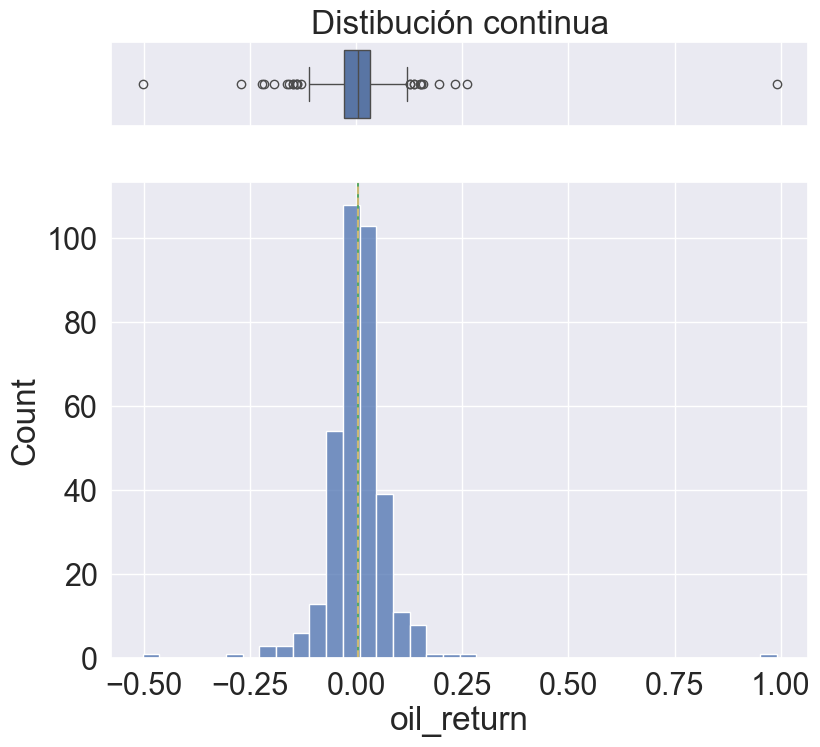

In [17]:
col = 'oil_return'
plot_col(df_merged[col])